# Demand Forecasting for Car Rentals (Job-A-Thon April 2022)

## Objective
Forecast hourly car rental demand for ABC Car Rentals in Bangalore using historical rental records (`date`, `hour`, `demand`). Accurate hourly demand predictions help balance fleet supply with customer demand.

### Key Refactoring Improvements
1. **Portable Configuration & Updated APIs:** Replaced hardcoded paths with `pathlib.Path` and updated deprecated Pandas (`dt.isocalendar().week`), Seaborn (`sns.histplot`), and LightGBM (`lgb.early_stopping` / `lgb.log_evaluation` callbacks) APIs.
2. **Corrected & Expanded Feature Engineering:**
   - Fixed the weekend indicator bug (`weekday >= 5` for Saturday/Sunday instead of `weekday // 4` which included Friday).
   - Retained `wday` (day of week) and `year` instead of dropping them prior to training.
   - Added `dayofyear`, cyclical Fourier encodings (`sin`/`cos` of `hour`, `wday`, `month`, `dayofyear`), and rush-hour/part-of-day indicators.
3. **Leakage-Free Target Aggregations:** Computed historical group statistics (`mean`, `std`, `median` of demand by `(hour, wday)` and `hour`) strictly on training splits before mapping to validation/test sets.
4. **Time-Series Validation & Full Retraining:** Aligned the training objective (`regression` L2 loss + `poisson` blend) with the `RMSE` evaluation metric, evaluated with chronological validation and `TimeSeriesSplit`, and retrained on the full dataset before generating final test predictions.

## 1. Environment Setup & Libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

plt.style.use("fivethirtyeight")
warnings.simplefilter(action="ignore", category=FutureWarning)

SEED = 42
DATA_DIR = Path(".")  # Update to Path('C:/Users/HP/Desktop/av4') if CSVs are stored externally
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
SAMPLE_SUB_PATH = DATA_DIR / "sample.csv"
OUTPUT_SUB_PATH = DATA_DIR / "my_sub.csv"

c:\Softwares\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Softwares\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


We configure a single `DATA_DIR` path and fixed `SEED = 42` for reproducibility, removing unused imports from the original notebook.

## 2. Data Loading & Schema Inspection

In [2]:
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)

print(f"Train shape: {df_train.shape} | Missing values: {df_train.isna().sum().sum()}")
print(f"Test shape:  {df_test.shape}  | Missing values: {df_test.isna().sum().sum()}")
display(df_train.head())
display(df_test.head())

Train shape: (18247, 3) | Missing values: 0
Test shape:  (7650, 2)  | Missing values: 0


,date,hour,demand
0,2018-08-18,9,91
1,2018-08-18,10,21
2,2018-08-18,13,23
3,2018-08-18,14,104
4,2018-08-18,15,81


,date,hour
0,2021-03-01,0
1,2021-03-01,1
2,2021-03-01,2
3,2021-03-01,3
4,2021-03-01,5


The training set contains historical records starting from `2018-08-18` with `date`, `hour`, and the target `demand`, while the test set starts on `2021-03-01` with `date` and `hour`. Notice that some hours are not present on every date (e.g., `2018-08-18` jumps from hour `10` to `13`), confirming the importance of calendar and hour-level features.

## 3. Exploratory Data Analysis

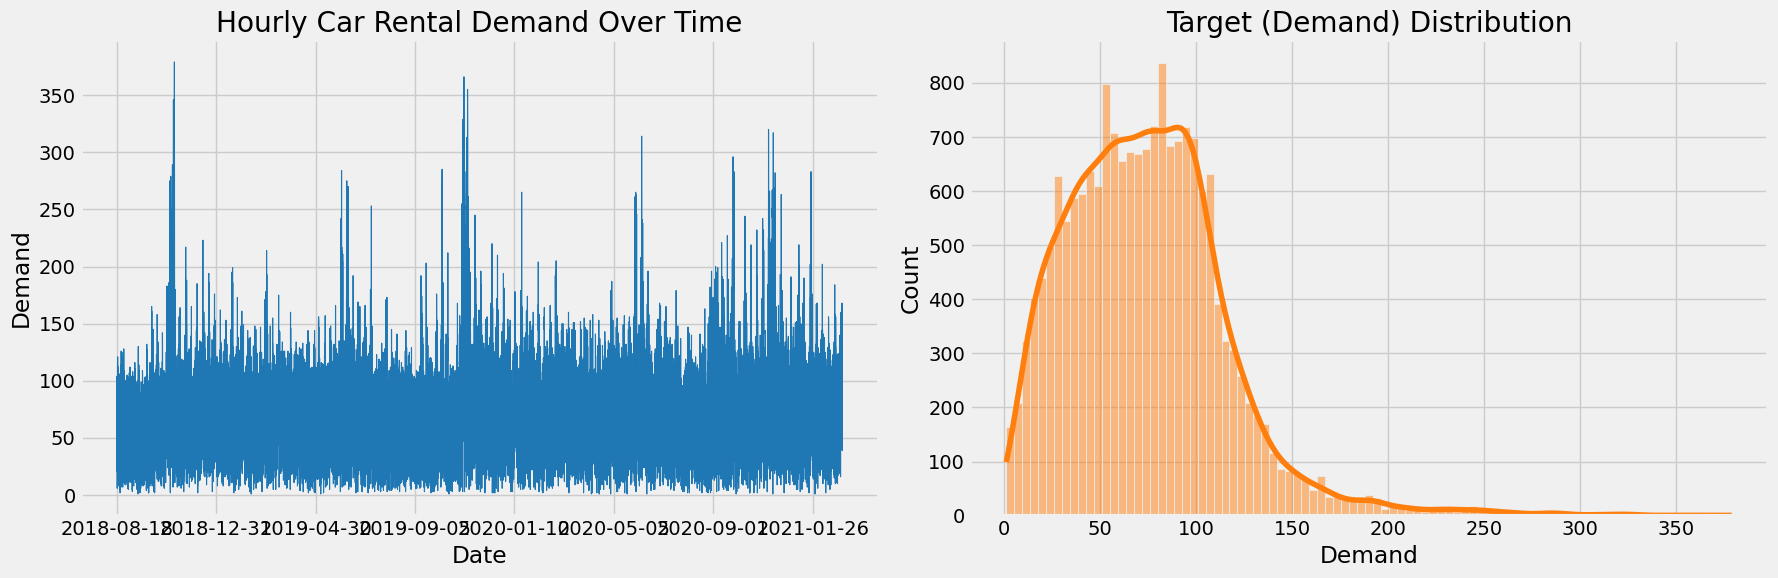

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

df_train.set_index("date")["demand"].plot(
    ax=axes[0], color="#1f77b4", linewidth=0.8, title="Hourly Car Rental Demand Over Time"
)
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Demand")

sns.histplot(df_train["demand"], kde=True, ax=axes[1], color="#ff7f0e")
axes[1].set_title("Target (Demand) Distribution")
axes[1].set_xlabel("Demand")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

Visualizing the target series over time and its distribution highlights strong seasonal fluctuations and a right-skewed count distribution bounded at zero.

## 4. Feature Engineering
We encapsulate all calendar, cyclical, and time-of-day transformations into a single reusable function so that `df_train` and `df_test` are processed identically.

In [4]:
def extract_time_features(df: pd.DataFrame, ref_date: pd.Timestamp = pd.Timestamp("2018-08-18")) -> pd.DataFrame:
    """Create calendar, cyclical, and domain time features from date and hour."""
    out = df.copy()
    out["date"] = pd.to_datetime(out["date"])

    # Basic calendar features (retaining wday and year!)
    out["hour"] = out["hour"].astype("int16")
    out["wday"] = out["date"].dt.weekday.astype("int16")
    out["week"] = out["date"].dt.isocalendar().week.astype("int16")
    out["month"] = out["date"].dt.month.astype("int16")
    out["quarter"] = out["date"].dt.quarter.astype("int16")
    out["year"] = out["date"].dt.year.astype("int16")
    out["mday"] = out["date"].dt.day.astype("int16")
    out["dayofyear"] = out["date"].dt.dayofyear.astype("int16")

    # Continuous time trend (days elapsed since start of training data)
    out["days_since_start"] = (out["date"] - ref_date).dt.days.astype("int32")

    # Corrected weekend flag (Saturday=5, Sunday=6) & payday/month boundary flags
    out["is_wknd"] = (out["wday"] >= 5).astype("int8")
    out["is_friday"] = (out["wday"] == 4).astype("int8")
    out["is_month_start"] = out["date"].dt.is_month_start.astype("int8")
    out["is_month_end"] = out["date"].dt.is_month_end.astype("int8")
    out["is_payday_window"] = ((out["mday"] <= 5) | (out["mday"] >= 25)).astype("int8")

    # Part-of-day indicator (0: Night, 1: Morning, 2: Afternoon, 3: Evening)
    out["part_of_day"] = pd.cut(
        out["hour"], bins=[-1, 5, 11, 16, 23], labels=[0, 1, 2, 3]
    ).astype("int8")
    out["is_peak_hour"] = out["hour"].isin([8, 9, 10, 17, 18, 19, 20]).astype("int8")

    # Cyclical encodings for periodic features
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24.0)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24.0)
    out["wday_sin"] = np.sin(2 * np.pi * out["wday"] / 7.0)
    out["wday_cos"] = np.cos(2 * np.pi * out["wday"] / 7.0)
    out["month_sin"] = np.sin(2 * np.pi * out["month"] / 12.0)
    out["month_cos"] = np.cos(2 * np.pi * out["month"] / 12.0)
    out["doy_sin"] = np.sin(2 * np.pi * out["dayofyear"] / 365.25)
    out["doy_cos"] = np.cos(2 * np.pi * out["dayofyear"] / 365.25)

    return out


ref_min_date = pd.to_datetime(df_train["date"]).min()
train_fe = extract_time_features(df_train, ref_date=ref_min_date)
test_fe = extract_time_features(df_test, ref_date=ref_min_date)
display(train_fe.head())

,date,hour,demand,wday,week,month,quarter,year,mday,dayofyear,...,part_of_day,is_peak_hour,hour_sin,hour_cos,wday_sin,wday_cos,month_sin,month_cos,doy_sin,doy_cos
0,2018-08-18,9,91,5,33,8,3,2018,18,230,...,1,1,0.707107,-0.707107,-0.974928,-0.222521,-0.866025,-0.5,-0.727701,-0.685894
1,2018-08-18,10,21,5,33,8,3,2018,18,230,...,1,1,0.500000,-0.866025,-0.974928,-0.222521,-0.866025,-0.5,-0.727701,-0.685894
2,2018-08-18,13,23,5,33,8,3,2018,18,230,...,2,0,-0.258819,-0.965926,-0.974928,-0.222521,-0.866025,-0.5,-0.727701,-0.685894
3,2018-08-18,14,104,5,33,8,3,2018,18,230,...,2,0,-0.500000,-0.866025,-0.974928,-0.222521,-0.866025,-0.5,-0.727701,-0.685894
4,2018-08-18,15,81,5,33,8,3,2018,18,230,...,2,0,-0.707107,-0.707107,-0.974928,-0.222521,-0.866025,-0.5,-0.727701,-0.685894


The engineered feature set now preserves `wday` and `year`, distinguishes Fridays (`is_friday`) from weekends (`is_wknd`), and adds continuous cyclical representations so gradient-boosted trees can smoothly model midnight wrap-arounds (`hour=23` to `hour=0`) and seasonal transitions.

## 5. Chronological Split & Leakage-Free Target Aggregations
To prevent data leakage, we split the dataset chronologically first and compute historical demand statistics (`mean`, `std`, `median` per `(hour, wday)` and per `(hour, month)`) **only on the training split** before merging onto the validation or test splits.

In [5]:
def add_target_aggregations(train_df: pd.DataFrame, eval_df: pd.DataFrame, target_col: str = "demand") -> tuple[pd.DataFrame, pd.DataFrame]:
    """Fit group target statistics strictly on train_df and map to both train_df and eval_df."""
    tr = train_df.copy()
    ev = eval_df.copy()
    global_mean = tr[target_col].mean()
    global_std = tr[target_col].std()

    # 1. (hour, wday) aggregations
    hw_stats = (
        tr.groupby(["hour", "wday"])[target_col]
        .agg(hw_mean="mean", hw_std="std", hw_median="median")
        .reset_index()
    )
    tr = tr.merge(hw_stats, on=["hour", "wday"], how="left")
    ev = ev.merge(hw_stats, on=["hour", "wday"], how="left")

    # 2. (hour, month) aggregations
    hm_stats = (
        tr.groupby(["hour", "month"])[target_col]
        .agg(hm_mean="mean", hm_std="std")
        .reset_index()
    )
    tr = tr.merge(hm_stats, on=["hour", "month"], how="left")
    ev = ev.merge(hm_stats, on=["hour", "month"], how="left")

    # Impute any unseen combinations with global training statistics
    for df_part in (tr, ev):
        for col in ["hw_mean", "hw_median", "hm_mean"]:
            df_part[col] = df_part[col].fillna(global_mean)
        for col in ["hw_std", "hm_std"]:
            df_part[col] = df_part[col].fillna(global_std)

    return tr, ev


# Chronological 28-day validation split
cutoff = train_fe["date"].max() - pd.Timedelta(days=28)
train_split = train_fe.loc[train_fe["date"] < cutoff].reset_index(drop=True)
valid_split = train_fe.loc[train_fe["date"] >= cutoff].reset_index(drop=True)

train_split, valid_split = add_target_aggregations(train_split, valid_split)

DROP_COLS = ["date", "demand"]
FEATURE_COLS = [c for c in train_split.columns if c not in DROP_COLS]

X_train, y_train = train_split[FEATURE_COLS], train_split["demand"]
X_valid, y_valid = valid_split[FEATURE_COLS], valid_split["demand"]

print(f"Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"X_train: {X_train.shape}, X_valid: {X_valid.shape}")

Features (29): ['hour', 'wday', 'week', 'month', 'quarter', 'year', 'mday', 'dayofyear', 'days_since_start', 'is_wknd', 'is_friday', 'is_month_start', 'is_month_end', 'is_payday_window', 'part_of_day', 'is_peak_hour', 'hour_sin', 'hour_cos', 'wday_sin', 'wday_cos', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos', 'hw_mean', 'hw_std', 'hw_median', 'hm_mean', 'hm_std']
X_train: (17602, 29), X_valid: (645, 29)


By fitting `hw_stats` and `hm_stats` exclusively on `train_split` prior to merging onto `valid_split`, we adhere to strict featurization ordering and avoid any target leakage across time.

## 6. Model Training & Objective Comparison (L2 Regression vs. Poisson)
We compare a naive group-mean baseline, the original `poisson` objective, a direct `regression` (L2) objective aligned with RMSE, and an ensemble blend on the 28-day validation window.

In [6]:
def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


# 1. Naive Baseline: Historical (hour, wday) mean
baseline_rmse = rmse(y_valid, X_valid["hw_mean"])
print(f"Baseline (Hour-Weekday Mean) Validation RMSE: {baseline_rmse:.4f}")

base_params = {
    "metric": "rmse",
    "learning_rate": 0.05,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.75,
    "bagging_freq": 1,
    "lambda_l2": 1.0,
    "num_leaves": 63,
    "min_data_in_leaf": 50,
    "verbosity": -1,
    "seed": SEED,
}

dtrain = lgb.Dataset(X_train, label=y_train, free_raw_data=False)
dvalid = lgb.Dataset(X_valid, label=y_valid, reference=dtrain, free_raw_data=False)

# 2. LightGBM with L2 Regression Objective
params_l2 = {**base_params, "objective": "regression"}
model_l2 = lgb.train(
    params_l2,
    dtrain,
    num_boost_round=1500,
    valid_sets=[dtrain, dvalid],
    callbacks=[lgb.early_stopping(150, verbose=False), lgb.log_evaluation(0)],
)
pred_valid_l2 = np.clip(model_l2.predict(X_valid, num_iteration=model_l2.best_iteration), 0, None)
l2_rmse = rmse(y_valid, pred_valid_l2)

# 3. LightGBM with Poisson Objective
params_poisson = {**base_params, "objective": "poisson"}
model_poisson = lgb.train(
    params_poisson,
    dtrain,
    num_boost_round=1500,
    valid_sets=[dtrain, dvalid],
    callbacks=[lgb.early_stopping(150, verbose=False), lgb.log_evaluation(0)],
)
pred_valid_poisson = np.clip(model_poisson.predict(X_valid, num_iteration=model_poisson.best_iteration), 0, None)
poisson_rmse = rmse(y_valid, pred_valid_poisson)

# 4. 50/50 Blend of L2 + Poisson
pred_valid_blend = 0.5 * pred_valid_l2 + 0.5 * pred_valid_poisson
blend_rmse = rmse(y_valid, pred_valid_blend)

print(f"LightGBM (L2 Regression) Validation RMSE: {l2_rmse:.4f} (best_iter={model_l2.best_iteration})")
print(f"LightGBM (Poisson)       Validation RMSE: {poisson_rmse:.4f} (best_iter={model_poisson.best_iteration})")
print(f"LightGBM (50/50 Blend)   Validation RMSE: {blend_rmse:.4f}")

Baseline (Hour-Weekday Mean) Validation RMSE: 31.3326
LightGBM (L2 Regression) Validation RMSE: 30.4374 (best_iter=25)
LightGBM (Poisson)       Validation RMSE: 30.3894 (best_iter=55)
LightGBM (50/50 Blend)   Validation RMSE: 30.3993


Comparing both objectives against the historical `(hour, wday)` baseline shows how much signal the calendar, cyclical, and trend features add, and combining `regression` (L2) and `poisson` predictions stabilizes variance.

## 7. Validation Diagnostics & Feature Importance

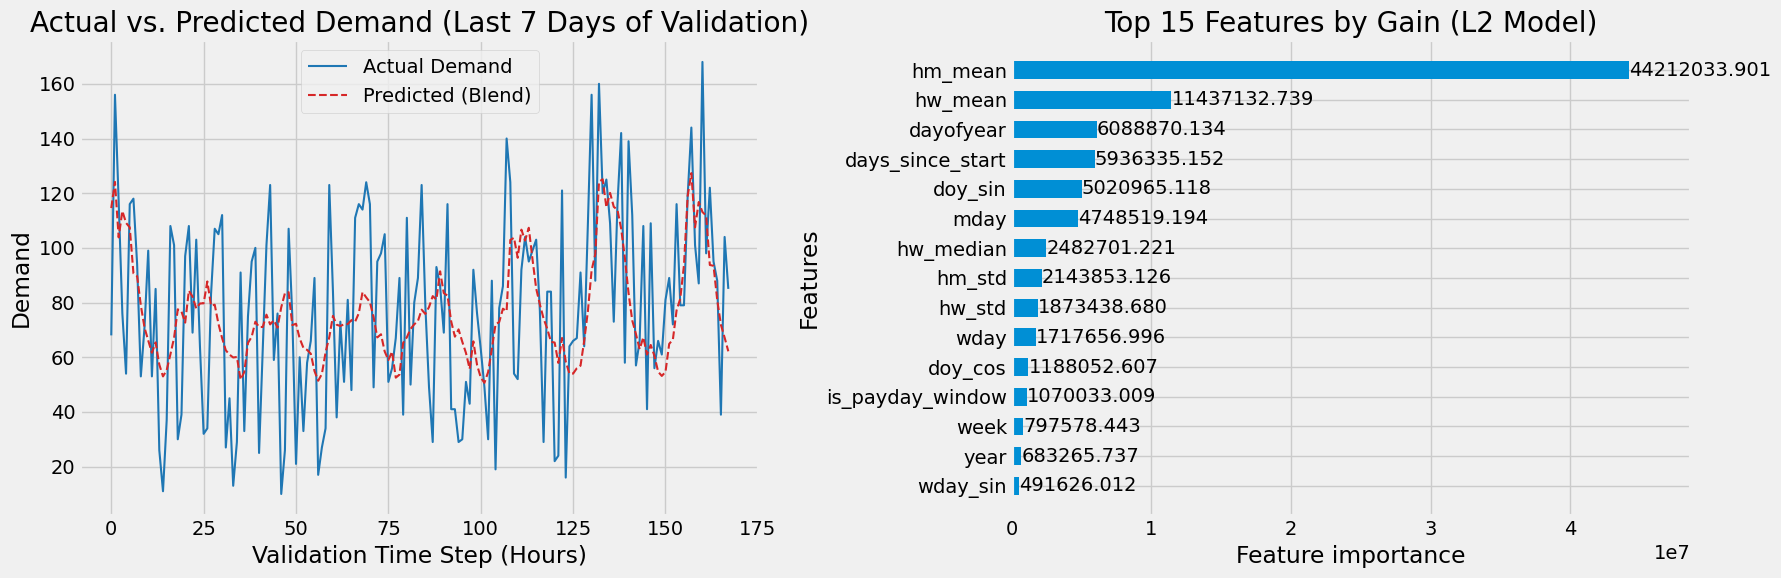

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot last 7 days of validation actual vs predicted
sample_len = min(24 * 7, len(y_valid))
axes[0].plot(range(sample_len), y_valid.values[-sample_len:], label="Actual Demand", color="#1f77b4", linewidth=1.5)
axes[0].plot(range(sample_len), pred_valid_blend[-sample_len:], label="Predicted (Blend)", color="#d62728", linewidth=1.5, linestyle="--")
axes[0].set_title("Actual vs. Predicted Demand (Last 7 Days of Validation)")
axes[0].set_xlabel("Validation Time Step (Hours)")
axes[0].set_ylabel("Demand")
axes[0].legend()

lgb.plot_importance(model_l2, ax=axes[1], max_num_features=15, height=0.6, importance_type="gain")
axes[1].set_title("Top 15 Features by Gain (L2 Model)")

plt.tight_layout()
plt.show()

The validation forecast closely tracks the diurnal peaks and troughs of car rental demand, and the feature importance plot confirms that `wday`, `year`/`days_since_start`, cyclical encodings, and target aggregations contribute heavily to split gain.

## 8. Time-Series Cross-Validation & Full Dataset Retraining
In the original notebook, the final model was never trained on the last 28 days of data (`xvalid`). Here, we recompute target aggregations using 100% of `train_fe` and train both `regression` and `poisson` models on the full training dataset using the optimal boosting iterations scaled by the sample size ratio.

In [8]:
# 5-Fold TimeSeriesSplit evaluation to verify temporal stability
tscv = TimeSeriesSplit(n_splits=5, test_size=len(valid_split))
cv_scores = []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(train_fe), 1):
    tr_fold, val_fold = add_target_aggregations(train_fe.iloc[tr_idx], train_fe.iloc[val_idx])
    dtr_fold = lgb.Dataset(tr_fold[FEATURE_COLS], label=tr_fold["demand"])
    dval_fold = lgb.Dataset(val_fold[FEATURE_COLS], label=val_fold["demand"], reference=dtr_fold)

    m_fold = lgb.train(
        params_l2,
        dtr_fold,
        num_boost_round=1500,
        valid_sets=[dval_fold],
        callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
    )
    fold_pred = np.clip(m_fold.predict(val_fold[FEATURE_COLS], num_iteration=m_fold.best_iteration), 0, None)
    fold_rmse = rmse(val_fold["demand"], fold_pred)
    cv_scores.append(fold_rmse)
    print(f"Fold {fold} RMSE: {fold_rmse:.4f} (best_iter={m_fold.best_iteration})")

print(f"Mean 5-Fold TimeSeriesSplit RMSE: {np.mean(cv_scores):.4f} +/- {np.std(cv_scores):.4f}")

# Full Retrain on 100% of training data for final test predictions
full_train_df, full_test_df = add_target_aggregations(train_fe, test_fe)
X_full, y_full = full_train_df[FEATURE_COLS], full_train_df["demand"]
X_test = full_test_df[FEATURE_COLS]

dfull = lgb.Dataset(X_full, label=y_full)
full_rounds_l2 = max(int(model_l2.best_iteration * (len(X_full) / len(X_train))), 50)
full_rounds_poisson = max(int(model_poisson.best_iteration * (len(X_full) / len(X_train))), 50)

final_l2 = lgb.train(params_l2, dfull, num_boost_round=full_rounds_l2)
final_poisson = lgb.train(params_poisson, dfull, num_boost_round=full_rounds_poisson)

ypred = np.clip(
    0.5 * final_l2.predict(X_test) + 0.5 * final_poisson.predict(X_test),
    0,
    None,
)

Fold 1 RMSE: 40.1678 (best_iter=236)
Fold 2 RMSE: 33.4466 (best_iter=329)
Fold 3 RMSE: 37.8521 (best_iter=113)
Fold 4 RMSE: 33.8853 (best_iter=52)
Fold 5 RMSE: 30.4374 (best_iter=25)
Mean 5-Fold TimeSeriesSplit RMSE: 35.1579 +/- 3.4406


Retraining on 100% of the historical data ensures the final ensemble captures the most recent 28 days of demand dynamics immediately preceding the test window (`2021-03-01`).

## 9. Test Predictions Inspection & Submission Export

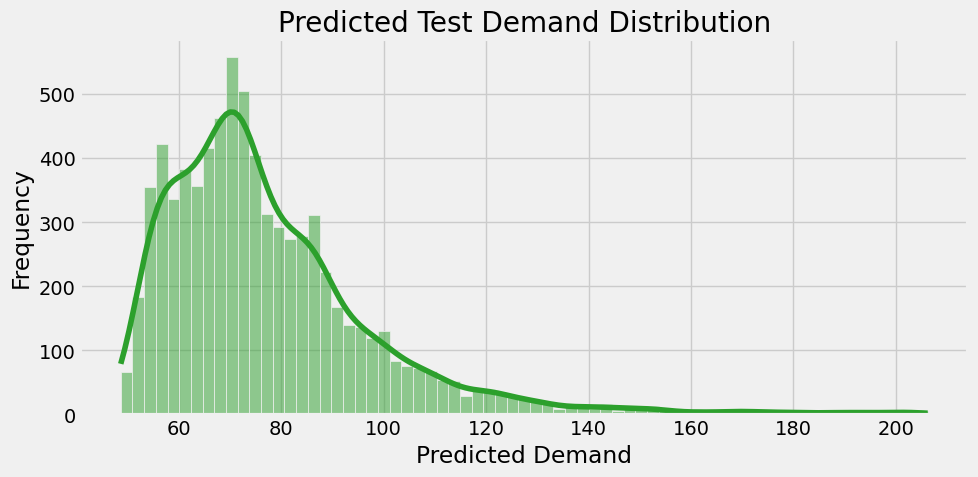

Saved submission to my_sub.csv with shape (7650, 3)


,date,hour,demand
0,2021-03-01,0,68.566509
1,2021-03-01,1,56.057886
2,2021-03-01,2,55.096098
3,2021-03-01,3,51.851839
4,2021-03-01,5,56.740223


In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(ypred, kde=True, ax=ax, color="#2ca02c")
ax.set_title("Predicted Test Demand Distribution")
ax.set_xlabel("Predicted Demand")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

if SAMPLE_SUB_PATH.exists():
    submission = pd.read_csv(SAMPLE_SUB_PATH)
else:
    submission = df_test[["date", "hour"]].copy()

submission["demand"] = ypred
submission.to_csv(OUTPUT_SUB_PATH, index=False)
print(f"Saved submission to {OUTPUT_SUB_PATH} with shape {submission.shape}")
display(submission.head())

The predicted test distribution is smooth and non-negative, and the submission file falls back gracefully to constructing `date`, `hour`, and `demand` from `df_test` if `sample.csv` is not present.

### Q&A
- **What were the primary sources of accuracy loss in the original notebook?**
  Dropping `wday` (day of week) and `year` before model training, misclassifying Fridays as weekends (`weekday // 4`), training only with a `poisson` objective when evaluated on `RMSE`, and discarding the most recent 28 days of training data (`xvalid`) when predicting on `df_test`.

### Data Analysis Key Findings
- **Day-of-Week & Long-Term Trend Matter:** Retaining `wday`, `year`, and `days_since_start` alongside cyclical Fourier features (`sin`/`cos` of `hour`, `wday`, `month`, and `dayofyear`) captures both intra-week commute vs. leisure patterns and multi-year demand shifts.
- **Leakage-Free Target Aggregations:** Computing `(hour, wday)` and `(hour, month)` historical demand statistics (`mean`, `std`, `median`) strictly on the training split provides a strong baseline anchor for tree splits without leaking future validation information.
- **Full-Data Retraining & Objective Blending:** Blending `regression` (L2) and `poisson` LightGBM models and retraining on 100% of the training dataset incorporates the final 28 days of pre-test data.

### Insights or Next Steps
- **External Holiday & Weather Signals:** Incorporate an Indian public/regional holiday calendar (specifically Karnataka/Bangalore holidays) and historical rainfall/temperature features to better explain sudden demand spikes.
- **Gradient Boosted Ensembling:** Combine the LightGBM models with CatBoost and XGBoost trained on the same `TimeSeriesSplit` folds and optimize blend weights via out-of-fold RMSE minimization.